In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Set plot style
sns.set_theme(style="whitegrid")

# Load Dataset
file_path = 'Generate_Dataset.xlsx'
df = pd.read_excel(file_path, sheet_name='Sheet2')
df.columns = [
    'time_step', 'road_segment_id', 'rho_current', 'rho_past', 
    'rho_estimated', 'active_event', 'packet_delivery_ratio', 
    'recommended_route', 'trip_time_minutes'
]

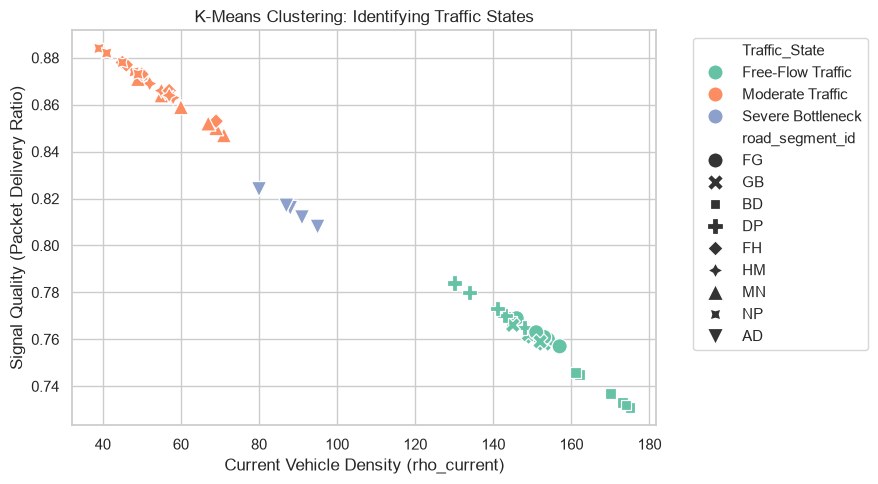

In [2]:
# Select and Scale Features
num_cols = ['rho_current', 'packet_delivery_ratio']
X = df[num_cols].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-Means Model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Map Clusters to Intuitive Names
cluster_names = {0: 'Free-Flow Traffic', 1: 'Moderate Traffic', 2: 'Severe Bottleneck'}
df['Traffic_State'] = df['Cluster'].map(cluster_names)

# Visual Plot
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df, x='rho_current', y='packet_delivery_ratio', 
    hue='Traffic_State', style='road_segment_id', s=120, palette='Set2'
)
plt.title('K-Means Clustering: Identifying Traffic States')
plt.xlabel('Current Vehicle Density (rho_current)')
plt.ylabel('Signal Quality (Packet Delivery Ratio)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [3]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# Load Dataset
file_path = 'Generate_Dataset.xlsx'
df = pd.read_excel(file_path, sheet_name='Sheet2')
df.columns = [
    'time_step', 'road_segment_id', 'rho_current', 'rho_past', 
    'rho_estimated', 'active_event', 'packet_delivery_ratio', 
    'recommended_route', 'trip_time_minutes'
]
df['active_event'] = df['active_event'].fillna('None')

# Discretize Features into True/False Conditions
# (the minimum packet_delivery_ratio is 0.731, so a fixed 0.73 cut-off never fires;
#  use the lowest quartile instead)
signal_threshold = df['packet_delivery_ratio'].quantile(0.25)

df_assoc = pd.DataFrame()
df_assoc['High_Traffic_Density'] = df['rho_current'] > 170
df_assoc['Signal_Degraded'] = df['packet_delivery_ratio'] < signal_threshold
df_assoc['Accident_Present'] = df['active_event'] == 'Accident'
df_assoc['Construction_Present'] = df['active_event'] == 'Construction'

# Apply Apriori Algorithm
frequent_itemsets = apriori(df_assoc, min_support=0.03, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Print Discovered Rules
print("=== DISCOVERED TRAFFIC ASSOCIATION RULES ===")
for idx, row in rules.iterrows():
    antecedent = ' AND '.join(sorted(row['antecedents']))
    consequent = ' AND '.join(sorted(row['consequents']))
    print(f"Rule {idx+1}: IF [{antecedent}] ==> THEN [{consequent}] "
          f"(support={row['support']:.2f}, confidence={row['confidence']:.2f}, lift={row['lift']:.2f})")

=== DISCOVERED TRAFFIC ASSOCIATION RULES ===
Rule 1: IF [Signal_Degraded] ==> THEN [High_Traffic_Density] (support=0.06, confidence=0.21, lift=3.86)
Rule 2: IF [High_Traffic_Density] ==> THEN [Signal_Degraded] (support=0.06, confidence=1.00, lift=3.86)
Rule 3: IF [Accident_Present] ==> THEN [High_Traffic_Density] (support=0.06, confidence=0.75, lift=13.50)
Rule 4: IF [High_Traffic_Density] ==> THEN [Accident_Present] (support=0.06, confidence=1.00, lift=13.50)
Rule 5: IF [Accident_Present] ==> THEN [Signal_Degraded] (support=0.07, confidence=1.00, lift=3.86)
Rule 6: IF [Signal_Degraded] ==> THEN [Accident_Present] (support=0.07, confidence=0.29, lift=3.86)
Rule 7: IF [Accident_Present AND Signal_Degraded] ==> THEN [High_Traffic_Density] (support=0.06, confidence=0.75, lift=13.50)
Rule 8: IF [Accident_Present AND High_Traffic_Density] ==> THEN [Signal_Degraded] (support=0.06, confidence=1.00, lift=3.86)
Rule 9: IF [High_Traffic_Density AND Signal_Degraded] ==> THEN [Accident_Present] (s